# IS403 - Walmart M5: Audited Features for 28-Day Machine Learning Forecasts

Build the shared supervised inputs for SVR, Random Forest and XGBoost on the
audited Level 1 daily series. This notebook creates and verifies features; it
does not train forecasting models or report forecast accuracy.

Run all cells on Kaggle CPU with the same processed dataset as notebooks 00-04.
Only `train.csv` and `val.csv` are read. No extra input, package installation,
Internet access, or path edit is required.

Each future target day is represented by a fixed feature rule and the same
fitted regression model will predict all 28 rows in a later notebook. Sales
lags are at least 28 days. Therefore, no future actual sales or recursively
generated predictions are required for the forecast feature matrix. This
conservative design uses older information at short horizons; it is not a
claim that every multi-step forecasting method must discard recent history.

In [1]:
from pathlib import Path
from importlib import metadata
from datetime import datetime, timezone
from time import perf_counter
from zipfile import ZipFile, ZIP_DEFLATED
import hashlib
import json
import platform
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = None
OUTPUT_DIR = None
SEED = 42
HORIZON = 28
ORIGINS = (1829, 1857, 1885)
LAGS = (28, 35, 42, 56)
ROLLING_SHIFT = 28
ROLLING_WINDOWS = (7, 28, 56)
FEATURE_GROUPS = ('lags', 'lags_calendar_events', 'lags_calendar_events_snap')
EXOG_COLUMNS = ['wday_iso', 'month', 'event_name_1', 'event_name_2',
                'snap_CA', 'snap_TX', 'snap_WI']
random.seed(SEED)
np.random.seed(SEED)
RUN_STARTED = perf_counter()

## 1. Verify the original Train/Validation inputs

The schema, dates, day IDs and canonical values must match the audited handoff.
The three forecast origins are the same as in notebooks 01, 03 and 04. The last
window is Validation. These adjacent windows are development windows, not an
independent final test and not a complete seasonal sample.

In [2]:
FILENAMES = ('train.csv', 'val.csv')


def find_data_directory(override=None):
    if override is not None:
        selected = Path(override).expanduser().resolve()
        if not all((selected / name).is_file() for name in FILENAMES):
            raise FileNotFoundError(f'Expected train.csv and val.csv in: {selected}')
        return selected

    candidates = set()
    for directory in [Path.cwd(), Path.cwd() / 'dataset',
                      Path.cwd() / '02_Data' / 'processed']:
        if all((directory / name).is_file() for name in FILENAMES):
            candidates.add(directory.resolve())

    root = Path('/kaggle/input')
    if root.is_dir():
        for path in root.rglob('train.csv'):
            if all((path.parent / name).is_file() for name in FILENAMES):
                candidates.add(path.parent.resolve())

    if not candidates:
        raise FileNotFoundError(
            'Attach the processed Kaggle dataset containing train.csv and val.csv, '
            'or set DATA_DIR explicitly.'
        )
    if len(candidates) > 1:
        options = '\n'.join(str(path) for path in sorted(candidates))
        raise ValueError(f'Multiple datasets found. Set DATA_DIR explicitly:\n{options}')
    return candidates.pop()


data_dir = find_data_directory(DATA_DIR)
output_dir = Path(OUTPUT_DIR) if OUTPUT_DIR is not None else (
    Path('/kaggle/working') if Path('/kaggle/working').is_dir()
    else Path.cwd() / 'ml_features_output'
)
print(f'Data: {data_dir}')
print(f'Output: {output_dir.resolve()}')

Data: /kaggle/input/datasets/nhntrnc/is403-m5-level-1
Output: /kaggle/working


In [3]:
EXPECTED_COLUMNS = ['d', 'date', 'total_sales', 'weekday', 'wday_iso', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
NUMERIC_COLUMNS = ['total_sales', 'wday_iso', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']
EVENT_COLUMNS = ['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']
REFERENCE_SHA256 = {'train': 'dcb9407590b16f6b975a1647c1c20f3cb932bc78dd75c1637f94d313c599d271', 'val': 'fbee2683fca3c5fc731b1d81829a56aa12c71e5b70ad124a1ac01ab3754536b5'}
SPLIT_DAYS = {'train': (1, 1885), 'val': (1886, 1913)}
FIRST_DATE = pd.Timestamp('2011-01-29')


def require(condition, message):
    if not condition:
        raise ValueError(message)


def table_sha256(frame):
    canonical_csv = frame[EXPECTED_COLUMNS].to_csv(index=False, lineterminator='\n')
    return hashlib.sha256(canonical_csv.encode('utf-8')).hexdigest()


def validate_split(name, directory):
    path = directory / f'{name}.csv'
    frame = pd.read_csv(path, keep_default_na=False)
    require(list(frame.columns) == EXPECTED_COLUMNS,
            f'{name}: columns or column order differ from the audited dataset.')

    first, last = SPLIT_DAYS[name]
    require(len(frame) == last - first + 1, f'{name}: incorrect row count.')
    require(frame['d'].tolist() == [f'd_{day}' for day in range(first, last + 1)],
            f'{name}: day IDs are missing, duplicated, or out of order.')
    dates = pd.to_datetime(frame['date'], format='%Y-%m-%d', errors='raise')
    expected_dates = pd.date_range(FIRST_DATE + pd.Timedelta(days=first - 1),
                                   periods=len(frame), freq='D')
    require(pd.DatetimeIndex(dates).equals(expected_dates),
            f'{name}: dates do not match the fixed chronological split.')
    require(not frame.duplicated(['d']).any() and not dates.duplicated().any(),
            f'{name}: duplicate day or date.')
    frame['date'] = dates.dt.strftime('%Y-%m-%d')

    for column in NUMERIC_COLUMNS:
        values = pd.to_numeric(frame[column], errors='raise')
        require(bool(np.isfinite(values.to_numpy()).all()),
                f'{name}: {column} contains missing or non-finite values.')
        require(bool((values % 1 == 0).all()), f'{name}: {column} must contain integers.')
        frame[column] = values.astype(np.int64)

    require(bool((frame['total_sales'] >= 0).all()), f'{name}: negative sales.')
    require(np.array_equal(frame['wday_iso'], dates.dt.dayofweek + 1),
            f'{name}: incorrect ISO weekday (Monday=1).')
    require(np.array_equal(frame['month'], dates.dt.month), f'{name}: incorrect month.')
    require(np.array_equal(frame['year'], dates.dt.year), f'{name}: incorrect year.')
    require(frame['weekday'].tolist() == dates.dt.day_name().tolist(),
            f'{name}: incorrect weekday names.')
    for column in ['snap_CA', 'snap_TX', 'snap_WI']:
        require(bool(frame[column].isin([0, 1]).all()), f'{name}: {column} is not binary.')
    for column in EVENT_COLUMNS:
        require(bool(frame[column].map(lambda value: isinstance(value, str)
                     and bool(value.strip())).all()),
                f'{name}: empty event labels; expected the literal string None.')

    fingerprint = table_sha256(frame)
    require(fingerprint == REFERENCE_SHA256[name],
            f'{name}: table values differ from the audited handoff. '
            'Use the audited original processed CSV files.')
    inventory = {
        'file': path.name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'first_day': frame['d'].iloc[0],
        'last_day': frame['d'].iloc[-1],
        'first_date': frame['date'].iloc[0],
        'last_date': frame['date'].iloc[-1],
        'table_sha256': fingerprint,
        'matches_audited_handoff': True,
    }
    return frame, inventory

In [4]:
frames = {}
input_inventory = []
for split in SPLIT_DAYS:
    frames[split], record = validate_split(split, data_dir)
    input_inventory.append(record)

development = pd.concat([frames['train'], frames['val']], ignore_index=True)
require(len(development) == 1913, 'Expected exactly 1,913 development days.')
require(development['d'].tolist() == [f'd_{day}' for day in range(1, 1914)],
        'Development data must be consecutive and end at d_1913.')
development['date'] = pd.to_datetime(development['date'])

fold_plan = pd.DataFrame([
    {
        'fold': fold,
        'origin_day': f'd_{origin}',
        'origin_date': development.iloc[origin - 1]['date'].strftime('%Y-%m-%d'),
        'history_rows': origin,
        'forecast_start': development.iloc[origin]['date'].strftime('%Y-%m-%d'),
        'forecast_end': development.iloc[origin + HORIZON - 1]['date'].strftime('%Y-%m-%d'),
    }
    for fold, origin in enumerate(ORIGINS, start=1)
])
print(pd.DataFrame(input_inventory)[['file', 'rows', 'columns',
                                    'matches_audited_handoff']].to_string(index=False))
print(fold_plan.to_string(index=False))
print('PASS: development data verified; test.csv has not been read.')

     file  rows  columns  matches_audited_handoff
train.csv  1885       14                     True
  val.csv    28       14                     True
 fold origin_day origin_date  history_rows forecast_start forecast_end
    1     d_1829  2016-01-31          1829     2016-02-01   2016-02-28
    2     d_1857  2016-02-28          1857     2016-02-29   2016-03-27
    3     d_1885  2016-03-27          1885     2016-03-28   2016-04-24
PASS: development data verified; test.csv has not been read.


## 2. Freeze the feature definitions and their information limits

For target day $t$, lag $\ell$ is $y_{t-\ell}$. A shifted rolling statistic
uses $y_{t-28-w+1},\ldots,y_{t-28}$ for window $w$. Rolling standard deviations
use population normalization (`ddof=0`). At an origin $T$, all sources for
$t=T+1,\ldots,T+28$ are at or before $T$.

| Group | Inputs |
|---|---|
| lags | Four sales lags plus means/stds for three shifted rolling windows. |
| lags_calendar_events | Historical features, six weekday indicators, month sine/cosine, and event-name indicators. |
| lags_calendar_events_snap | The preceding inputs plus separate CA, TX and WI SNAP flags. |

An event indicator combines the two event-name slots. The vocabulary is fitted
on usable supervised training rows only. Unknown future names map to zeros and
are logged. Future weekday, month, events and SNAP are known calendar inputs.
Prices and event-type labels are not used as additional features.

The first 83 historical target rows are unavailable because the longest
rolling window requires 83 past days. Training targets therefore start at
`d_84`. There is no random split. The full and reduced feature groups share
exactly the same training/forecast rows.

In [5]:
HISTORY_RULES = {}
for lag in LAGS:
    HISTORY_RULES[f'lag_{lag}'] = {'kind': 'lag', 'lag': lag,
                                  'minimum_offset': lag, 'maximum_offset': lag}
for window in ROLLING_WINDOWS:
    for statistic in ('mean', 'std'):
        HISTORY_RULES[f'rolling_{statistic}_{window}_shift_{ROLLING_SHIFT}'] = {
            'kind': 'rolling_' + statistic, 'window': window,
            'minimum_offset': ROLLING_SHIFT,
            'maximum_offset': ROLLING_SHIFT + window - 1}
HISTORY_COLUMNS = list(HISTORY_RULES)
CALENDAR_COLUMNS = [f'weekday_{day}' for day in range(2, 8)] + ['month_sin', 'month_cos']
SNAP_COLUMNS = ['snap_CA', 'snap_TX', 'snap_WI']
WARMUP = max(rule['maximum_offset'] for rule in HISTORY_RULES.values())
require(WARMUP == 83, 'Unexpected historical warm-up.')
require(all(rule['minimum_offset'] >= HORIZON for rule in HISTORY_RULES.values()),
        'A historical feature can access sales after the forecast origin.')


def historical_features(sales):
    values = pd.Series(np.asarray(sales, dtype=np.float64))
    result = pd.DataFrame(index=values.index)
    for lag in LAGS:
        result[f'lag_{lag}'] = values.shift(lag)
    shifted = values.shift(ROLLING_SHIFT)
    for window in ROLLING_WINDOWS:
        rolling = shifted.rolling(window, min_periods=window)
        result[f'rolling_mean_{window}_shift_{ROLLING_SHIFT}'] = rolling.mean()
        result[f'rolling_std_{window}_shift_{ROLLING_SHIFT}'] = rolling.std(ddof=0)
    require(list(result.columns) == HISTORY_COLUMNS, 'Historical column order changed.')
    return result


def event_names(frame):
    return sorted({str(v) for column in ['event_name_1', 'event_name_2']
                   for v in frame[column] if str(v) != 'None'})


def known_calendar_features(frame, vocabulary):
    require(list(frame.columns) == EXOG_COLUMNS,
            'Calendar feature input must exclude targets and unapproved columns.')
    result = pd.DataFrame(index=frame.index)
    for day in range(2, 8):
        result[f'weekday_{day}'] = (frame['wday_iso'].to_numpy() == day).astype(float)
    angle = 2 * np.pi * (frame['month'].to_numpy(dtype=float) - 1) / 12
    result['month_sin'], result['month_cos'] = np.sin(angle), np.cos(angle)
    for index, name in enumerate(vocabulary):
        result[f'event_{index:02d}'] = (
            frame['event_name_1'].eq(name) | frame['event_name_2'].eq(name)).astype(float)
    for column in SNAP_COLUMNS:
        result[column] = frame[column].to_numpy(dtype=float)
    return result.reset_index(drop=True)


def build_feature_bundle(history, known_future):
    require(len(known_future) == HORIZON, 'Expected 28 known future calendar rows.')
    require(list(known_future.columns) == EXOG_COLUMNS,
            'Do not pass future actual sales into the feature builder.')
    origin = len(history)
    require(origin > WARMUP, 'Insufficient history.')
    y = history['total_sales'].to_numpy(dtype=float)
    usable = np.arange(WARMUP, origin)
    train_known = history.iloc[usable][EXOG_COLUMNS].reset_index(drop=True)
    vocabulary = event_names(train_known)
    train_h = historical_features(y).iloc[usable].reset_index(drop=True)
    # Missing placeholders deliberately prevent access to any forecast-window actual.
    future_h = historical_features(np.r_[y, np.full(HORIZON, np.nan)]).iloc[origin:]
    future_h = future_h.reset_index(drop=True)
    train_c = known_calendar_features(train_known, vocabulary)
    future_c = known_calendar_features(known_future.reset_index(drop=True), vocabulary)
    X_train = pd.concat([train_h, train_c], axis=1)
    X_future = pd.concat([future_h, future_c], axis=1)
    require(np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_future.to_numpy()).all(),
            'Feature matrices contain missing or non-finite values.')
    require(list(X_train.columns) == list(X_future.columns), 'Feature schemas differ.')
    means = X_train.mean(axis=0).to_numpy(dtype=float)
    raw_stds = X_train.std(axis=0, ddof=0).to_numpy(dtype=float)
    scales = np.where(raw_stds > 0, raw_stds, 1.0)
    groups = {
        'lags': HISTORY_COLUMNS,
        'lags_calendar_events': [c for c in X_train.columns if c not in SNAP_COLUMNS],
        'lags_calendar_events_snap': list(X_train.columns),
    }
    schema = {
        'origin_day': origin, 'warmup_rows': WARMUP,
        'training_rows': len(usable), 'forecast_rows': HORIZON,
        'training_first_day': WARMUP + 1, 'training_last_day': origin,
        'columns': list(X_train.columns), 'groups': groups,
        'event_vocabulary': vocabulary,
        'event_column_mapping': {f'event_{i:02d}': name for i, name in enumerate(vocabulary)},
        'unseen_future_events': sorted(set(event_names(known_future)) - set(vocabulary)),
        'scaler_fit_rows': len(X_train), 'scaler_ddof': 0,
        'scaler_mean': means.tolist(), 'scaler_scale': scales.tolist(),
        'constant_training_columns': [c for c, std in zip(X_train.columns, raw_stds) if std == 0],
        'target_transform': 'none; original sales units',
    }
    return {'X_train': X_train.to_numpy(dtype=float),
            'X_future': X_future.to_numpy(dtype=float),
            'X_train_scaled': (X_train.to_numpy(dtype=float) - means) / scales,
            'X_future_scaled': (X_future.to_numpy(dtype=float) - means) / scales,
            'y_train': y[usable].copy(),
            'train_day': usable + 1,
            'future_day': np.arange(origin + 1, origin + HORIZON + 1),
            'schema': schema}

## 3. Build each development fold independently

Each origin receives its own training prefix, event vocabulary and feature
scaler. No schema or fitted preprocessing from a later fold is reused in an
earlier one. Scalers are learned from usable training features, never from
future rows. Unscaled matrices support tree models; standardized matrices
support SVR. A later SVR notebook must also fit any target scaler on training
targets only and restore predictions to original sales units before scoring.

Evaluation targets are copied separately only after the features are frozen.
They are provided for later scoring and never enter the feature constructor.

In [6]:
bundles = {}
fold_summary_rows = []
dictionary_rows = []
for fold, origin in enumerate(ORIGINS, start=1):
    history = development.iloc[:origin].copy()
    future_known = development.iloc[origin:origin + HORIZON][EXOG_COLUMNS].copy()
    bundle = build_feature_bundle(history, future_known)
    bundle['y_future'] = development.iloc[origin:origin + HORIZON]['total_sales'].to_numpy(dtype=float)
    schema = bundle['schema']
    bundles[fold] = bundle
    fold_summary_rows.append({
        'fold': fold, 'origin_day': origin, 'training_rows': schema['training_rows'],
        'training_first_day': schema['training_first_day'], 'training_last_day': origin,
        'forecast_rows': HORIZON, 'forecast_first_day': origin + 1,
        'forecast_last_day': origin + HORIZON,
        'lags_features': len(schema['groups']['lags']),
        'calendar_event_features': len(schema['groups']['lags_calendar_events']),
        'full_features': len(schema['columns']),
        'unseen_event_count': len(schema['unseen_future_events']),
        'scaler_fit_rows': schema['scaler_fit_rows'],
    })
    for index, name in enumerate(schema['columns']):
        rule = HISTORY_RULES.get(name, {})
        dictionary_rows.append({
            'fold': fold, 'feature': name,
            'family': ('historical_sales' if name in HISTORY_RULES else
                       'SNAP' if name in SNAP_COLUMNS else
                       'event' if name in schema['event_column_mapping'] else 'calendar'),
            'event_name': schema['event_column_mapping'].get(name, ''),
            'minimum_sales_offset': rule.get('minimum_offset', ''),
            'maximum_sales_offset': rule.get('maximum_offset', ''),
            'training_mean': schema['scaler_mean'][index],
            'training_scale': schema['scaler_scale'][index],
            'in_lags': name in schema['groups']['lags'],
            'in_lags_calendar_events': name in schema['groups']['lags_calendar_events'],
            'in_lags_calendar_events_snap': True,
        })
    print(f'Fold {fold}: {schema["training_rows"]} training rows; '
          f'{len(schema["columns"])} features; 28 forecast rows.')

fold_summary = pd.DataFrame(fold_summary_rows)
feature_dictionary = pd.DataFrame(dictionary_rows)
print(fold_summary.to_string(index=False))

Fold 1: 1746 training rows; 51 features; 28 forecast rows.
Fold 2: 1774 training rows; 51 features; 28 forecast rows.
Fold 3: 1802 training rows; 51 features; 28 forecast rows.
 fold  origin_day  training_rows  training_first_day  training_last_day  forecast_rows  forecast_first_day  forecast_last_day  lags_features  calendar_event_features  full_features  unseen_event_count  scaler_fit_rows
    1        1829           1746                  84               1829             28                1830               1857             10                       48             51                   0             1746
    2        1857           1774                  84               1857             28                1858               1885             10                       48             51                   0             1774
    3        1885           1802                  84               1885             28                1886               1913             10                       48    

## 4. Verify information availability and preprocessing isolation

The checks below are part of the experiment protocol. Every forecast feature's
latest historical source must be at or before its origin. Independent scalar
calculations verify all historical features on all 84 forecast rows. Adversarial
future sales and event-name changes must leave fitted training preprocessing
unchanged. Changing future sales must also leave the entire forecast feature
matrix unchanged. Unknown future events may change their reported metadata,
but cannot add learned event columns.

In [7]:
check_rows = []


def record_check(fold, name, condition, detail):
    require(bool(condition), f'Fold {fold}: {name} failed.')
    check_rows.append({'fold': fold, 'check': name, 'passed': True, 'detail': detail})


for fold, origin in enumerate(ORIGINS, start=1):
    bundle = bundles[fold]
    schema = bundle['schema']
    history_values = development.iloc[:origin]['total_sales'].to_numpy(dtype=float)
    latest_sources = []
    independent = []
    for target_day in bundle['future_day']:
        expected = []
        for name, rule in HISTORY_RULES.items():
            end_day = int(target_day) - rule['minimum_offset']
            start_day = int(target_day) - rule['maximum_offset']
            latest_sources.append(end_day)
            require(1 <= start_day <= end_day <= origin, 'Historical source exceeds origin.')
            values = history_values[start_day - 1:end_day].tolist()
            if rule['kind'] == 'lag':
                value = values[0]
            else:
                average = sum(values) / len(values)
                value = average if rule['kind'] == 'rolling_mean' else (
                    sum((x - average) ** 2 for x in values) / len(values)) ** 0.5
            expected.append(value)
        independent.append(expected)
    record_check(fold, 'historical_source_dates', max(latest_sources) <= origin,
                 f'Latest historical source is d_{max(latest_sources)}; origin is d_{origin}.')
    record_check(fold, 'independent_historical_values',
                 np.allclose(bundle['X_future'][:, :len(HISTORY_COLUMNS)], independent,
                             rtol=1e-11, atol=1e-7),
                 'All 28 rows x 10 historical features match scalar calculations.')
    record_check(fold, 'target_alignment',
                 np.array_equal(bundle['train_day'], np.arange(WARMUP + 1, origin + 1))
                 and np.array_equal(bundle['future_day'], np.arange(origin + 1, origin + 29)),
                 'Training targets end at the origin; forecast targets are the next 28 days.')
    train = bundle['X_train']
    expected_mean = train.mean(axis=0)
    expected_scale = train.std(axis=0, ddof=0)
    expected_scale = np.where(expected_scale > 0, expected_scale, 1.0)
    record_check(fold, 'train_only_scaling',
                 schema['scaler_fit_rows'] == len(train)
                 and np.allclose(schema['scaler_mean'], expected_mean, rtol=1e-12, atol=1e-12)
                 and np.allclose(schema['scaler_scale'], expected_scale, rtol=1e-12, atol=1e-12)
                 and np.allclose(bundle['X_future_scaled'],
                                 (bundle['X_future'] - expected_mean) / expected_scale),
                 'Means/stds use only usable supervised training rows.')
    # Future labels are deliberately poisoned in a separate copy of the frame.
    poisoned = development.iloc[:origin + HORIZON].copy()
    poisoned.loc[poisoned.index >= origin, 'total_sales'] = -123456789
    rebuilt = build_feature_bundle(poisoned.iloc[:origin],
                                   poisoned.iloc[origin:][EXOG_COLUMNS])
    invariant = all(np.array_equal(bundle[key], rebuilt[key]) for key in
                    ['X_train', 'X_future', 'X_train_scaled', 'X_future_scaled', 'y_train'])
    record_check(fold, 'future_sales_invariance', invariant,
                 'Poisoning all forecast-window actual sales changes no model input.')
    future_known = development.iloc[origin:origin + HORIZON][EXOG_COLUMNS].copy()
    future_known['event_name_1'] = '__UNSEEN_FUTURE_EVENT__'
    perturbed = build_feature_bundle(development.iloc[:origin], future_known)
    record_check(fold, 'future_event_fit_isolation',
                 np.array_equal(bundle['X_train'], perturbed['X_train'])
                 and np.array_equal(bundle['X_train_scaled'], perturbed['X_train_scaled'])
                 and schema['event_vocabulary'] == perturbed['schema']['event_vocabulary']
                 and schema['scaler_mean'] == perturbed['schema']['scaler_mean']
                 and schema['scaler_scale'] == perturbed['schema']['scaler_scale']
                 and '__UNSEEN_FUTURE_EVENT__' not in perturbed['schema']['event_vocabulary'],
                 'Future event names cannot alter training vocabulary or scaling.')
    record_check(fold, 'finite_matrices', all(np.isfinite(bundle[key]).all() for key in
                 ['X_train', 'X_future', 'X_train_scaled', 'X_future_scaled']),
                 'No missing/infinite input remains after historical warm-up.')
    columns = schema['columns']
    record_check(fold, 'nested_feature_groups',
                 schema['groups']['lags'] == columns[:len(HISTORY_COLUMNS)]
                 and schema['groups']['lags_calendar_events'] == columns[:-3]
                 and columns[-3:] == SNAP_COLUMNS,
                 'All ablation groups share identical rows and retain three separate SNAP flags.')

leakage_checks = pd.DataFrame(check_rows)
require(len(leakage_checks) == 24 and leakage_checks['passed'].all(), 'Incomplete audit.')
print(leakage_checks[['fold', 'check', 'passed']].to_string(index=False))

 fold                         check  passed
    1       historical_source_dates    True
    1 independent_historical_values    True
    1              target_alignment    True
    1            train_only_scaling    True
    1       future_sales_invariance    True
    1    future_event_fit_isolation    True
    1               finite_matrices    True
    1         nested_feature_groups    True
    2       historical_source_dates    True
    2 independent_historical_values    True
    2              target_alignment    True
    2            train_only_scaling    True
    2       future_sales_invariance    True
    2    future_event_fit_isolation    True
    2               finite_matrices    True
    2         nested_feature_groups    True
    3       historical_source_dates    True
    3 independent_historical_values    True
    3              target_alignment    True
    3            train_only_scaling    True
    3       future_sales_invariance    True
    3    future_event_fit_isolat

## 5. Inspect the latest sales source used by each feature

The heatmap shows source-day offsets relative to the final development origin
`d_1885`. Zero means the origin day; negative values are older observations.
For rolling features, this is the most recent day in the rolling window. No
cell may be positive. The figure is an availability check, not forecast output
or evidence of predictive feature importance.

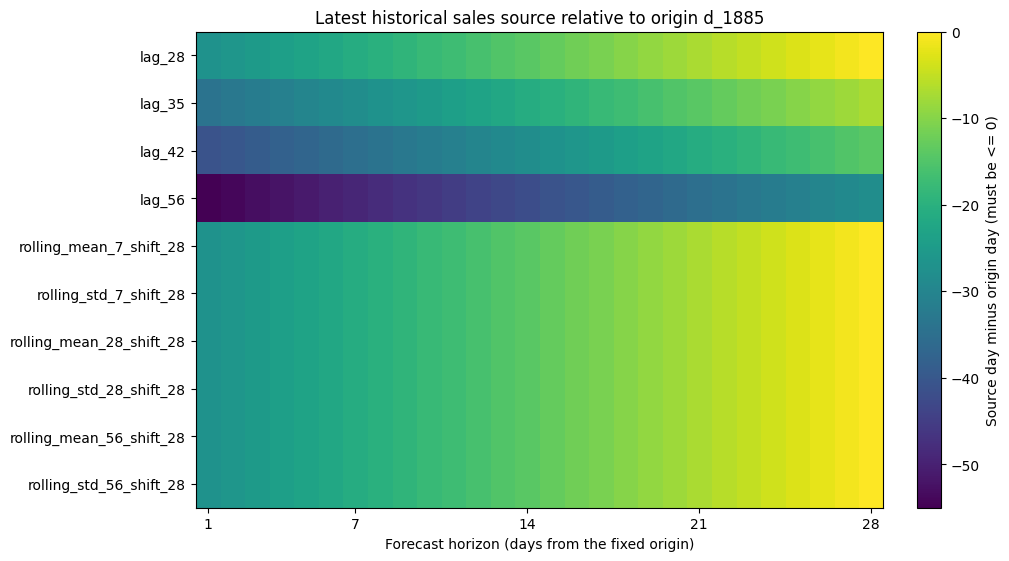

In [8]:
offsets = np.array([[h - rule['minimum_offset'] for h in range(1, HORIZON + 1)]
                    for rule in HISTORY_RULES.values()])
require(offsets.max() == 0, 'Unexpected historical source availability.')
fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')
image = ax.imshow(offsets, aspect='auto', cmap='viridis', vmin=int(offsets.min()), vmax=0)
ax.set_yticks(range(len(HISTORY_COLUMNS)), HISTORY_COLUMNS)
ax.set_xticks([0, 6, 13, 20, 27], [1, 7, 14, 21, 28])
ax.set_xlabel('Forecast horizon (days from the fixed origin)')
ax.set_title('Latest historical sales source relative to origin d_1885')
fig.colorbar(image, ax=ax, label='Source day minus origin day (must be <= 0)')
plt.show()

## 6. Export the reusable matrices and audit evidence

Each NPZ file contains raw and standardized feature matrices, original-unit
targets, ordered feature names and day IDs. Load with `np.load(...,
allow_pickle=False)` in later model notebooks. Select the declared group using
the manifest's ordered feature names. Never fit a model on `y_future` or reuse
a later fold's scaler in an earlier fold.

Full data matrices belong on Drive only. Small feature dictionaries, audit
tables, the figure and JSON metadata can also be archived in GitHub after the
actual Kaggle run has been checked. No model is selected in this notebook.

In [9]:
data_output = output_dir / '02_Data' / 'processed' / 'ml_features'
artifact_output = output_dir / '04_Outputs_and_Artifacts'
table_output, figure_output = artifact_output / 'table', artifact_output / 'figures'
for directory in [data_output, table_output, figure_output]:
    directory.mkdir(parents=True, exist_ok=True)
exported_paths = []
matrix_records = []
for fold, bundle in bundles.items():
    path = data_output / f'ml_features_fold_{fold}.npz'
    np.savez_compressed(path,
        **{key: bundle[key] for key in ['X_train', 'X_future', 'X_train_scaled',
           'X_future_scaled', 'y_train', 'y_future', 'train_day', 'future_day']},
        feature_names=np.array(bundle['schema']['columns'], dtype='U'))
    with np.load(path, allow_pickle=False) as saved:
        require(np.array_equal(saved['X_train'], bundle['X_train'])
                and np.array_equal(saved['X_future'], bundle['X_future'])
                and saved['feature_names'].tolist() == bundle['schema']['columns'],
                'Exported matrix round-trip failed.')
    exported_paths.append(path)
    matrix_records.append({'fold': fold, 'path': path.relative_to(output_dir).as_posix(),
                           'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
                           'schema': bundle['schema']})
for name, frame in [('ml_feature_dictionary.csv', feature_dictionary),
                    ('ml_feature_fold_summary.csv', fold_summary),
                    ('ml_feature_leakage_checks.csv', leakage_checks)]:
    path = table_output / name
    frame.to_csv(path, index=False)
    exported_paths.append(path)
figure_path = figure_output / 'ml_feature_source_availability.png'
fig.savefig(figure_path, dpi=300)
exported_paths.append(figure_path)
manifest = {
    'schema_version': 1, 'forecast_strategy': 'fixed-rule target-day regression; no recursion',
    'horizon': HORIZON, 'origins': list(ORIGINS), 'seed': SEED,
    'history_rules': HISTORY_RULES, 'feature_groups': list(FEATURE_GROUPS),
    'preprocessing': 'fold-specific event vocabulary and train-only population standardization',
    'target_units': 'original Level 1 units; no target transformation',
    'data_fingerprints': {row['file']: row['table_sha256'] for row in input_inventory},
    'matrix_files': matrix_records,
    'test_labels_read': False, 'test_features_computed': False,
}
manifest_path = artifact_output / 'ml_feature_manifest.json'
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
exported_paths.append(manifest_path)
versions = {}
for name in ['numpy', 'pandas', 'matplotlib']:
    versions[name] = metadata.version(name)
report = {
    'status': 'PASS', 'created_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'versions': versions,
    'files_read': ['train.csv', 'val.csv'], 'test_labels_read': False,
    'test_features_computed': False, 'forecast_models_trained': 0,
    'folds': fold_summary.to_dict(orient='records'),
    'checks_passed': int(leakage_checks['passed'].sum()),
    'checks_total': len(leakage_checks),
    'data_fingerprints': manifest['data_fingerprints'],
    'elapsed_seconds_before_packaging': perf_counter() - RUN_STARTED,
    'files': [path.relative_to(output_dir).as_posix() for path in exported_paths],
}
report_path = artifact_output / 'ml_feature_run_report.json'
report_path.write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
exported_paths.append(report_path)
zip_path = output_dir / '05_ml_features_results.zip'
with ZipFile(zip_path, 'w', compression=ZIP_DEFLATED) as archive:
    for path in exported_paths:
        archive.write(path, path.relative_to(output_dir).as_posix())
with ZipFile(zip_path) as archive:
    require(archive.testzip() is None and len(archive.namelist()) == 9,
            'Export archive is incomplete.')

print('ML FEATURE CHECK PASSED')
print(f'Folds: {len(bundles)}; forecast rows per fold: {HORIZON}; checks: 24/24')
print(f'Warm-up: {WARMUP}; final training rows: {len(bundles[3]["y_train"])}')
print('Models trained: 0; test.csv read: False')
print(f'Download: {zip_path}')

ML FEATURE CHECK PASSED
Folds: 3; forecast rows per fold: 28; checks: 24/24
Warm-up: 83; final training rows: 1802
Models trained: 0; test.csv read: False
Download: /kaggle/working/05_ml_features_results.zip


## Scope and next experiment

This artifact fixes and audits candidate input definitions before model tuning;
it does not prove that these lags/windows are optimal. Later development runs
will compare the three feature groups using Validation, retain all search logs,
and report the chosen group and its limitations. Scores across the three nearby
windows remain development scores because Validation also participates in model
selection. Final Test evaluation follows only after all choices are frozen.

References: the project plan's temporal-split/feature rules;
[scikit-learn: leakage and training-only preprocessing](https://scikit-learn.org/stable/common_pitfalls.html);
[scikit-learn: lagged feature example](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html).
The example's one-step lag settings are not copied into this 28-day protocol.